# Motivation

From the learnings in the `identifiability_and_cramer_rao` crusade, we learned how to compute the rank of the tangent space Jacobian of our model. This allows us to numerically estimate the number of learnable degrees of freedom of the model. In principle, as we are not in one of the "defective" points in the manifold, the rank should be the same. In theory, the exact number should be 


$$\min(3 N, \text{GST}_{\text{min}})$$

with $N$ the number of sequences and $\text{GST}_{\text{min}}$ the theoretical lower bound on the number of parameters after quotienting the Gauge degrees of freedom.

# Goal:

In this notebook, we want to verify a few things:

1. Compare the rank obtained for different points, i.e. the true gate set, the perturbed initialization of the optimization (and perhaps final optimized one)? ✅

2. Verify which of these achieve the theoretical bound. ✅

Importantly, this is only a measurement of learnability in the inifinite shots limit, without any notion of how well this are actually learned in practice. That is what the next crusade will be about, making use of the eigenvalues to compute standard deviations.

In [1]:
%load_ext autoreload
%autoreload 2

from mGST.gauge_analysis import probability_jacobian_spectrum
from mGST.utility_functions_comparisons import get_target_operators_gate_set_name, get_compressed_rep_from_mgst_output, kraus_tensor_to_mgst, get_initial_gate_set_for_optimization

from mGST.simulate import apply_noisy_kraus_tensors_to_target_gate_set, get_random_noisy_kraus_tensors_for_gate_set, generate_sequence_indices, generate_random_initial_operators
from mGST.gauge_analysis import probability_jacobian_spectrum, min_num_parameters
from mGST.visualization import plot_cost_function

import jax.numpy as jnp

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Parameters

In [2]:
seq_len_list = [1, 8, 14]
num_qubits = 2
dim = 2 ** num_qubits
state_rank = dim # max
povm_rank = dim # max
kraus_rank = 4 # start with a small rank
num_gates = 6
num_povm = dim
gate_set_name = "2QXYICZ"
noise_strength = 0.3

title_general = rf"{num_qubits}Q | $r_\mathrm{{Kraus}}$: {kraus_rank} | $r_\mathrm{{POVM}}$: {povm_rank} | $r_\mathrm{{State}}$: {state_rank}"

In [3]:
min_expected = min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank, povm_rank=povm_rank, kraus_rank=kraus_rank)
min_expected

623

In [4]:
min_num_parameters(num_qubits=num_qubits, num_gates=num_gates, state_rank=state_rank-1, povm_rank=povm_rank-1, kraus_rank=kraus_rank-1)

468

In [5]:
6 * 96

576

# Tensors generations

In [6]:
target_operators, gate_labels = get_target_operators_gate_set_name(gate_set_name=gate_set_name)

random_kraus_tensors = get_random_noisy_kraus_tensors_for_gate_set(
    num_gates=num_gates,
    dim=dim,
    rank_kraus=kraus_rank,
    noise_strength=noise_strength,
    seed=42
)

noisy_gate_set_superop = apply_noisy_kraus_tensors_to_target_gate_set(
    kraus_tensors_noisy=random_kraus_tensors,
    target_gate_set=target_operators,
    is_target_vectorized=True,
)

kraus_tensor_noisy, povm_psd_noisy, state_psd_noisy = get_compressed_rep_from_mgst_output(
    *noisy_gate_set_superop.values(),
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

kraus_target_superop = kraus_tensor_to_mgst(target_operators["kraus"])

target_gate_set_superops = {
    "kraus": kraus_target_superop,
    "povm": target_operators["povm"],
    "state": target_operators["state"],
}

kraus_tensor_target, povm_psd_target, state_psd_target = get_compressed_rep_from_mgst_output(
    *target_gate_set_superops.values(), 
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank)

target_gate_set_psd = {
    "kraus": kraus_tensor_target,
    "povm": povm_psd_target,
    "state": state_psd_target,
}

# Gathering them all in one place
noisy_gate_set_psd = {
    "kraus": kraus_tensor_noisy,
    "povm": povm_psd_noisy,
    "state": state_psd_noisy,
}

spam_depolarization = 1e-2

init_gate_set_psd = get_initial_gate_set_for_optimization(
    target_superops=target_gate_set_superops,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank,
    spam_depolarization=spam_depolarization,
    project_kraus_to_isometry=True, # because it is max rank, even false would return an isometry
)


INFO:2026-11-16 21:53:51,133:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
2026-11-16 21:53:51,133 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2026-11-16 21:53:51,136:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/

In [7]:
noisy_gate_set_psd

kraus_deficient = noisy_gate_set_psd["kraus"].copy()
kraus_padded = jnp.pad(kraus_deficient, ((0, 0), (0, 4), (0, 0), (0, 0)))
rank_deficient_gate_set_psd = {
    "kraus": kraus_padded,
    "povm": noisy_gate_set_psd["povm"].copy(),
    "state": noisy_gate_set_psd["state"].copy()
}

In [8]:
random_gate_set_psd = generate_random_initial_operators(
    num_gates=num_gates,
    dim=dim,
    kraus_rank=kraus_rank,
    state_rank=state_rank,
    povm_rank=povm_rank
)

# Generation for fixed length across different num. sequences

In [9]:
# here we can define a helper function to help us compute the rank given a collection of sequences
number_of_sequences_list = [50, 100, 150, 200, 205, 208, 210, 215, 250, 300, 400]
num_shots = 1000
seq_len_list = [1, 8, 14]

In [10]:
def compute_results_for_number_of_sequences(num_sequences, gate_set_psd:dict[str, jnp.ndarray], seq_len_list: list, num_shots: int | None = None, seed: int | None = None):
    kraus_tensor = gate_set_psd["kraus"]
    povm_psd = gate_set_psd["povm"]
    state_psd = gate_set_psd["state"]
    num_gates = kraus_tensor.shape[0]
    
    indices = generate_sequence_indices(num_gates=num_gates, num_circuits=num_sequences, seq_len_list=seq_len_list, seed=seed)["gate_indices"]
    result_idx = probability_jacobian_spectrum(kraus_tensor, povm_psd, state_psd, indices_list=indices, num_shots=num_shots)
    return result_idx

def compute_results_for_all_number_of_sequences(number_of_sequences_list, gate_set_psd:dict[str, jnp.ndarray], seq_len_list, num_shots:int|None = None, seed: int | None = None):
    results = []
    for i, num_sequences in enumerate(number_of_sequences_list):
        print(f"Computing results for {num_sequences} sequences... ({i+1}/{len(number_of_sequences_list)})")
        result_idx = compute_results_for_number_of_sequences(num_sequences, gate_set_psd, seq_len_list, num_shots, seed=seed)
        results.append(result_idx)
    return results

def compute_results_for_all_depths(depth_list, gate_set_psd:dict[str, jnp.ndarray], number_of_sequences, num_shots:int|None = None, seed: int | None = None):
    results = []
    for i, max_depth in enumerate(depth_list):
        print(f"Computing results for sequence length {max_depth}... ({i+1}/{len(depth_list)})")
        seq_len_list = [1, max_depth //2, max_depth]
        result_idx = compute_results_for_number_of_sequences(number_of_sequences, gate_set_psd, seq_len_list, num_shots, seed=seed)
        results.append(result_idx)
    return results

In [11]:
results_true_gate_set = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=noisy_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [12]:
longer_sequences_list = [500, 600, 700, 800, 900, 1000]

In [13]:
number_of_sequences_list, seq_len_list

([50, 100, 150, 200, 205, 208, 210, 215, 250, 300, 400], [1, 8, 14])

In [14]:
results_true_gate_set_longer_sequences = compute_results_for_all_number_of_sequences(number_of_sequences_list=longer_sequences_list, gate_set_psd=noisy_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 500 sequences... (1/6)
Computing results for 600 sequences... (2/6)
Computing results for 700 sequences... (3/6)
Computing results for 800 sequences... (4/6)
Computing results for 900 sequences... (5/6)
Computing results for 1000 sequences... (6/6)


In [15]:
results_unitary_gate_set = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=target_gate_set_psd, seq_len_list=seq_len_list)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [16]:
results_random_gate_set = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=random_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


In [ ]:
results_init_gate_set = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=init_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)


In [ ]:
results_rank_defficient_gate_set = compute_results_for_all_number_of_sequences(number_of_sequences_list=number_of_sequences_list, gate_set_psd=rank_deficient_gate_set_psd, seq_len_list=seq_len_list, num_shots=num_shots)

Computing results for 50 sequences... (1/11)
Computing results for 100 sequences... (2/11)
Computing results for 150 sequences... (3/11)
Computing results for 200 sequences... (4/11)
Computing results for 205 sequences... (5/11)
Computing results for 208 sequences... (6/11)
Computing results for 210 sequences... (7/11)
Computing results for 215 sequences... (8/11)
Computing results for 250 sequences... (9/11)
Computing results for 300 sequences... (10/11)
Computing results for 400 sequences... (11/11)


# Structural identiability

In [ ]:
ranks_true_gate_set_1000_shots = [result["rank"] for result in results_true_gate_set]
ranks_unitary_gate_set_1000_shots = [result["rank"] for result in results_unitary_gate_set]
ranks_random_gate_set_1000_shots = [result["rank"] for result in results_random_gate_set]
ranks_init_gate_set_1000_shots = [result["rank"] for result in results_init_gate_set]
ranks_rank_deficient_gate_set_1000_shots = [result["rank"] for result in results_rank_defficient_gate_set]

ranks_expected = [min(3 * num_sequences, min_expected + 1) for num_sequences in number_of_sequences_list]

In [ ]:
ranks_true_gate_set_1000_shots[-1] - ranks_unitary_gate_set_1000_shots[-1]

95

In [ ]:
ranks_unitary_gate_set_1000_shots

[136, 271, 397, 515, 524, 529, 529, 529, 529, 529, 529]

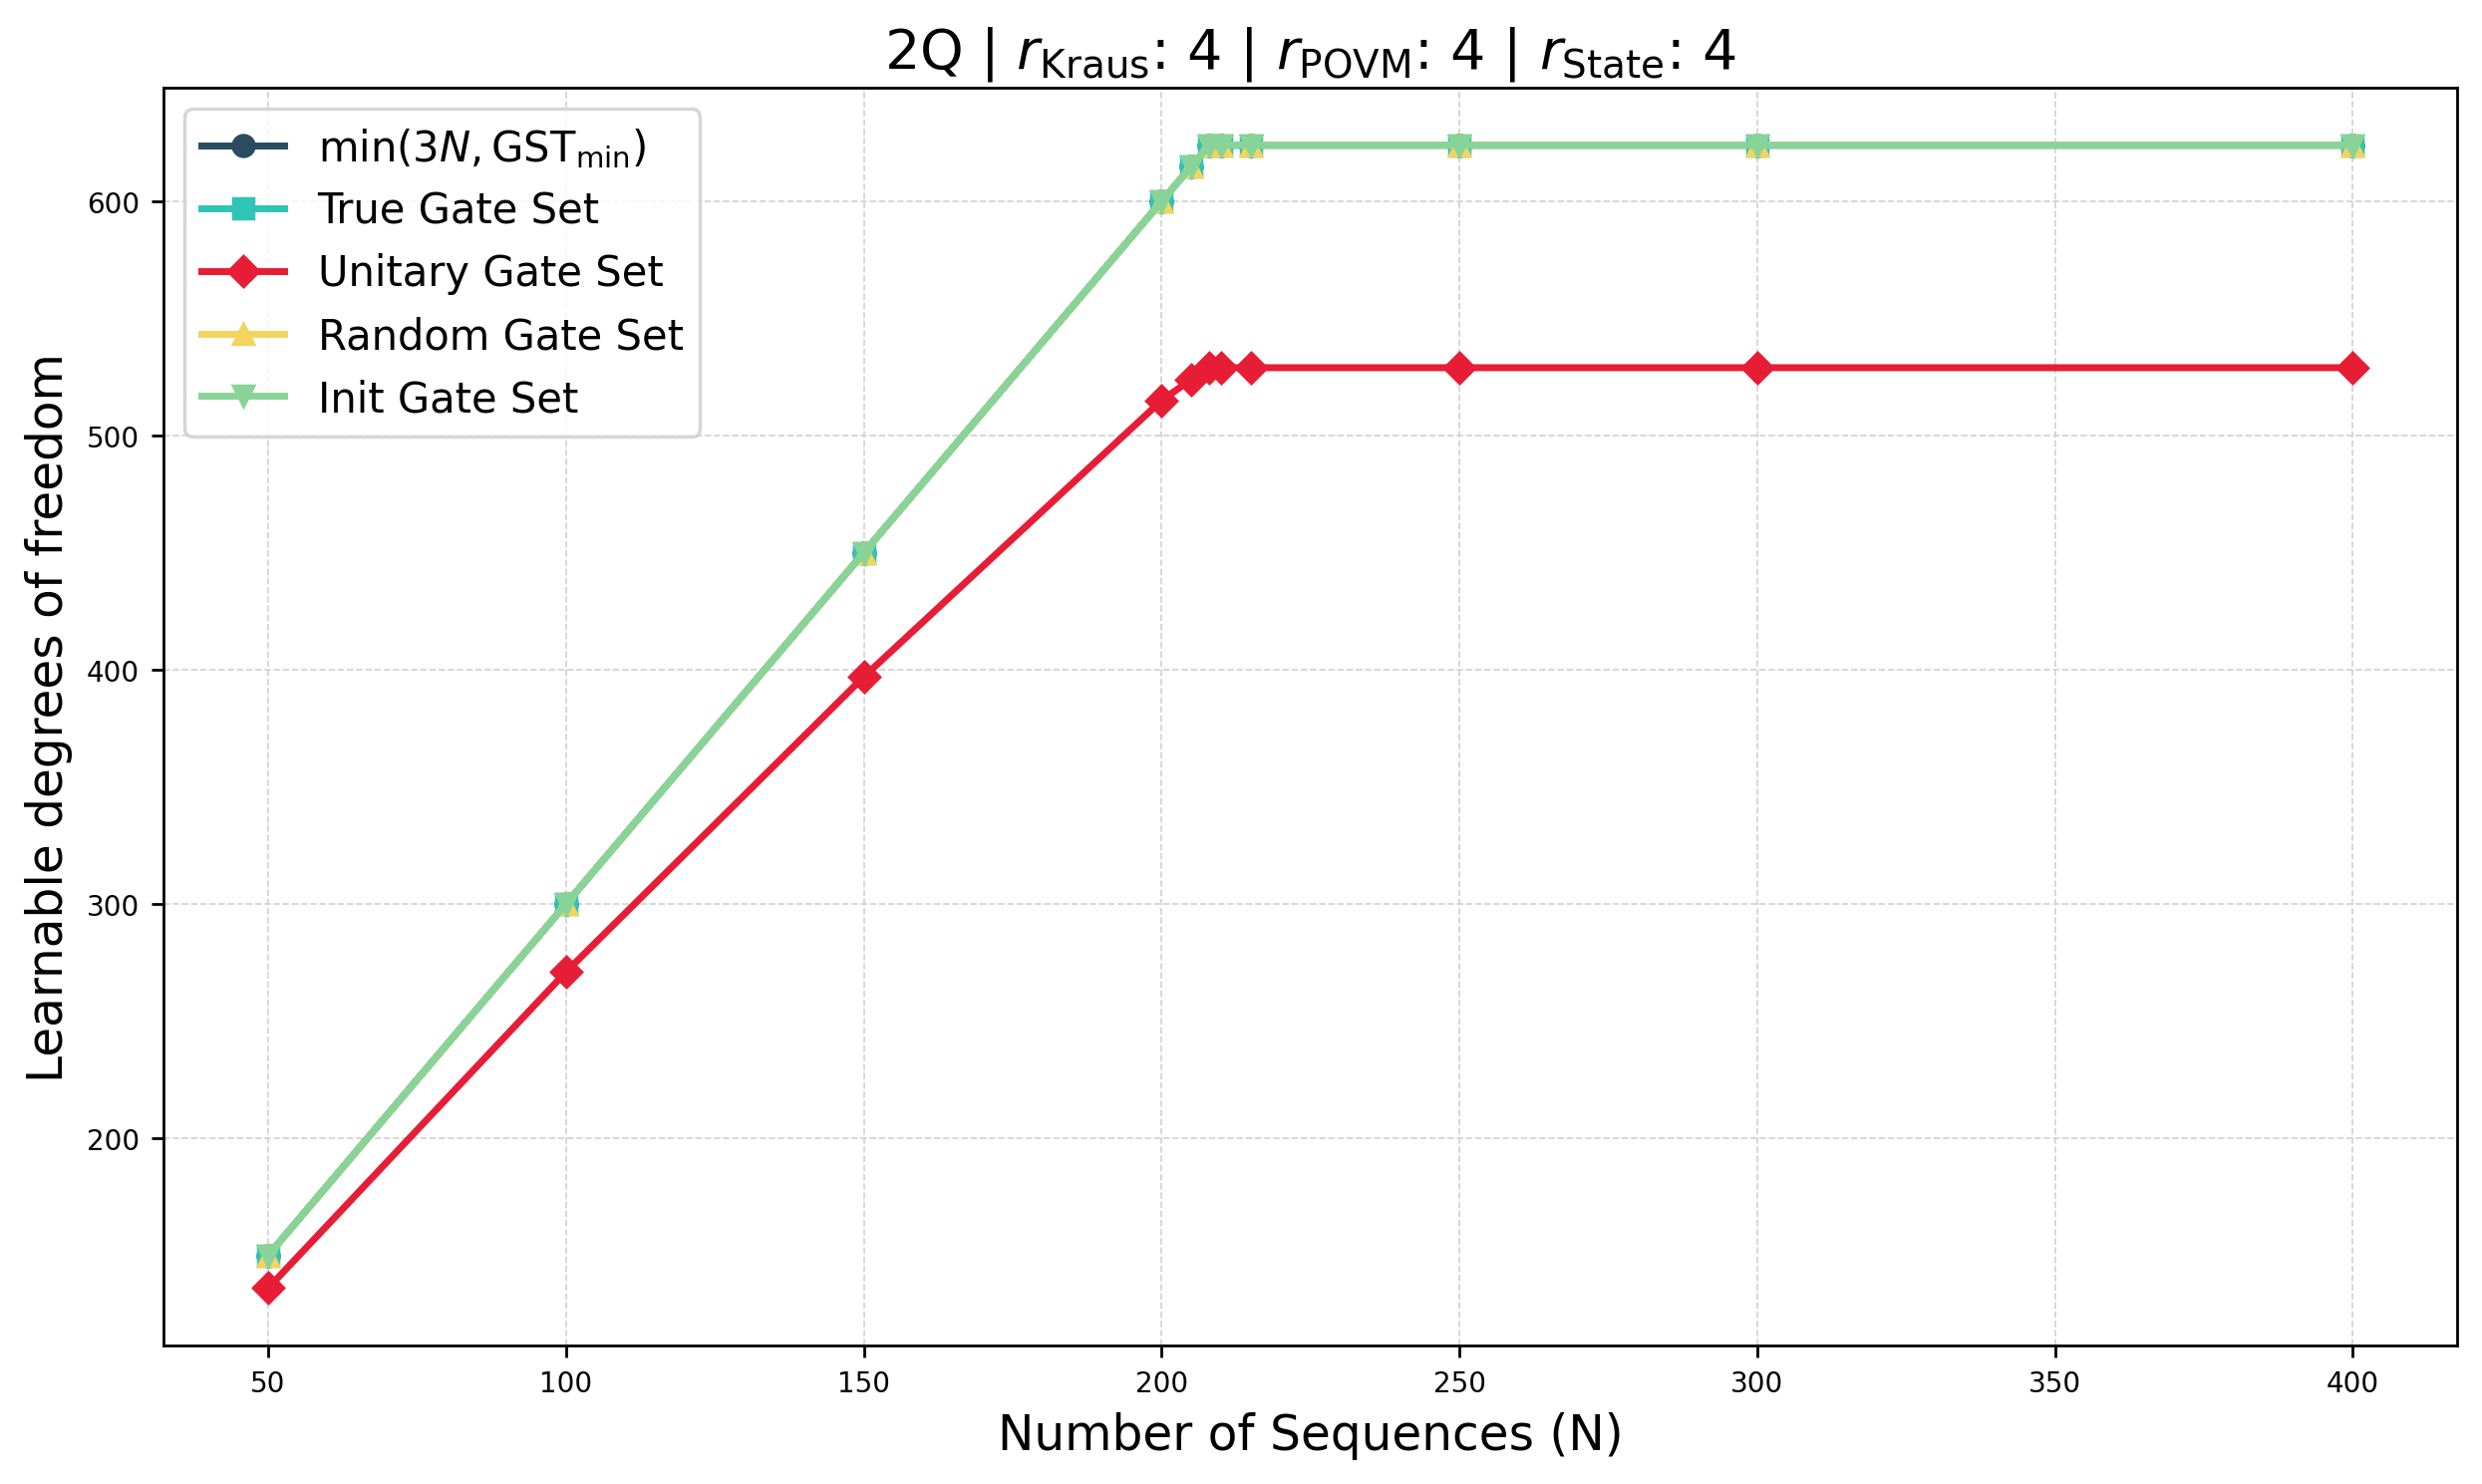

In [180]:
ranks_arrays = [ranks_expected, ranks_true_gate_set_1000_shots, ranks_unitary_gate_set_1000_shots, ranks_random_gate_set_1000_shots, ranks_init_gate_set_1000_shots]#ranks_rank_deficient_gate_set_1000_shots]

labels_array = [r"$\text{min}(3 N, \text{GST}_{\text{min}})$", "True Gate Set", "Unitary Gate Set", "Random Gate Set", "Init Gate Set"] #"Rank Deficient Gate Set"]

plot_cost_function(
    cost_array=ranks_arrays,
    labels=labels_array,
    x_array=number_of_sequences_list,
    use_semilogy=False,
    xlabel="Number of Sequences (N)",
    ylabel="Learnable degrees of freedom",
    title=title_general,
)

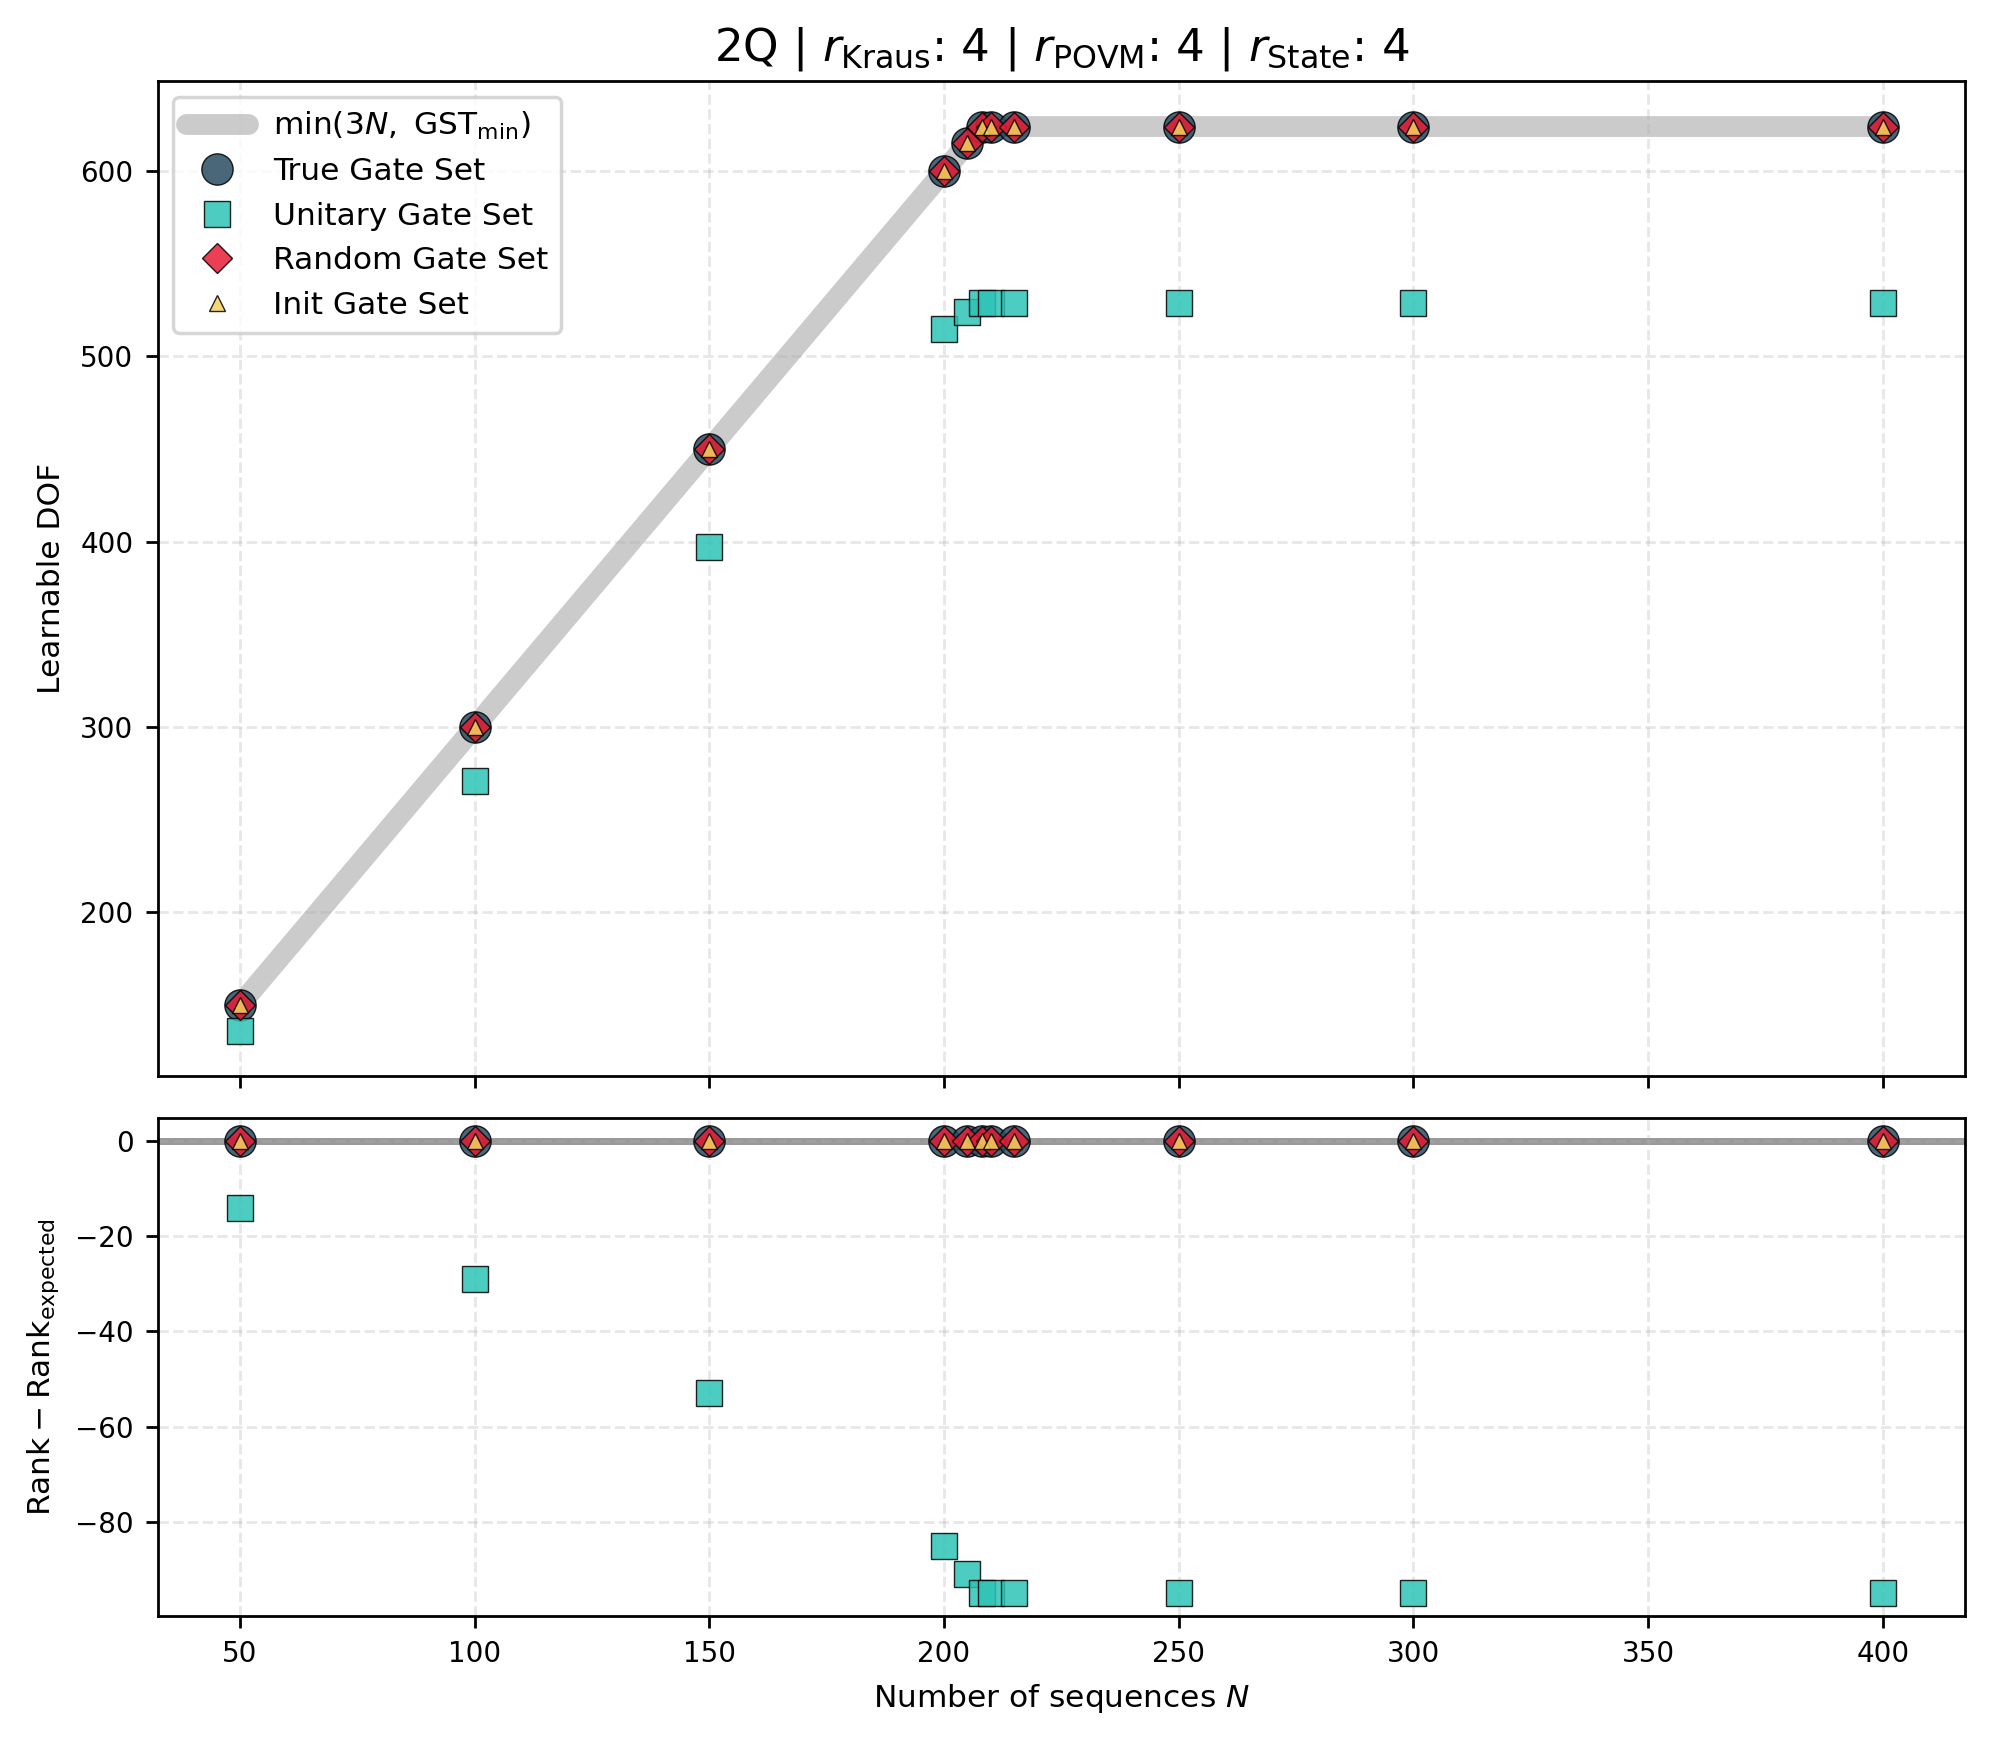

In [186]:
import matplotlib.pyplot as plt
from mGST.visualization import COLOUR_PALETTE, MARKERS

fig, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(8, 7), dpi=250, sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

# Top: absolute ranks, expected drawn as a thick background guide
ax0.plot(number_of_sequences_list, ranks_expected, color="0.6", linewidth=6,
         alpha=0.5, solid_capstyle="round", label=r"$\min(3N,\ \mathrm{GST}_{\min})$", zorder=0)

for i, (ranks, label) in enumerate(zip(ranks_arrays[1:], labels_array[1:])):
    ax0.plot(number_of_sequences_list, ranks, linestyle="none",
             marker=MARKERS[i], markersize=9 - 1.5 * i, alpha=0.85,
             color=COLOUR_PALETTE[i], markeredgecolor="black",
             markeredgewidth=0.4, label=label)

ax0.set_ylabel("Learnable DOF")
ax0.set_title(title_general, fontsize=13)
ax0.grid(alpha=0.3, linestyle="--")
ax0.legend(fontsize=9)

# Bottom: residual w.r.t. the bound
ax1.axhline(0, color="0.6", linewidth=2, zorder=0)
for i, (ranks, label) in enumerate(zip(ranks_arrays[1:], labels_array[1:])):
    residual = [r - e for r, e in zip(ranks, ranks_expected)]
    ax1.plot(number_of_sequences_list, residual, linestyle="none",
             marker=MARKERS[i], markersize=9 - 1.5 * i, alpha=0.85,
             color=COLOUR_PALETTE[i], markeredgecolor="black", markeredgewidth=0.4)

ax1.set_xlabel("Number of sequences $N$")
ax1.set_ylabel(r"$\text{Rank} - \text{Rank}_{\mathrm{expected}}$")
ax1.grid(alpha=0.3, linestyle="--")
fig.tight_layout()

/var/folders/1z/5qqk4w_97cz44w7c72srsw2c0000gq/T/ipykernel_97311/1533072876.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


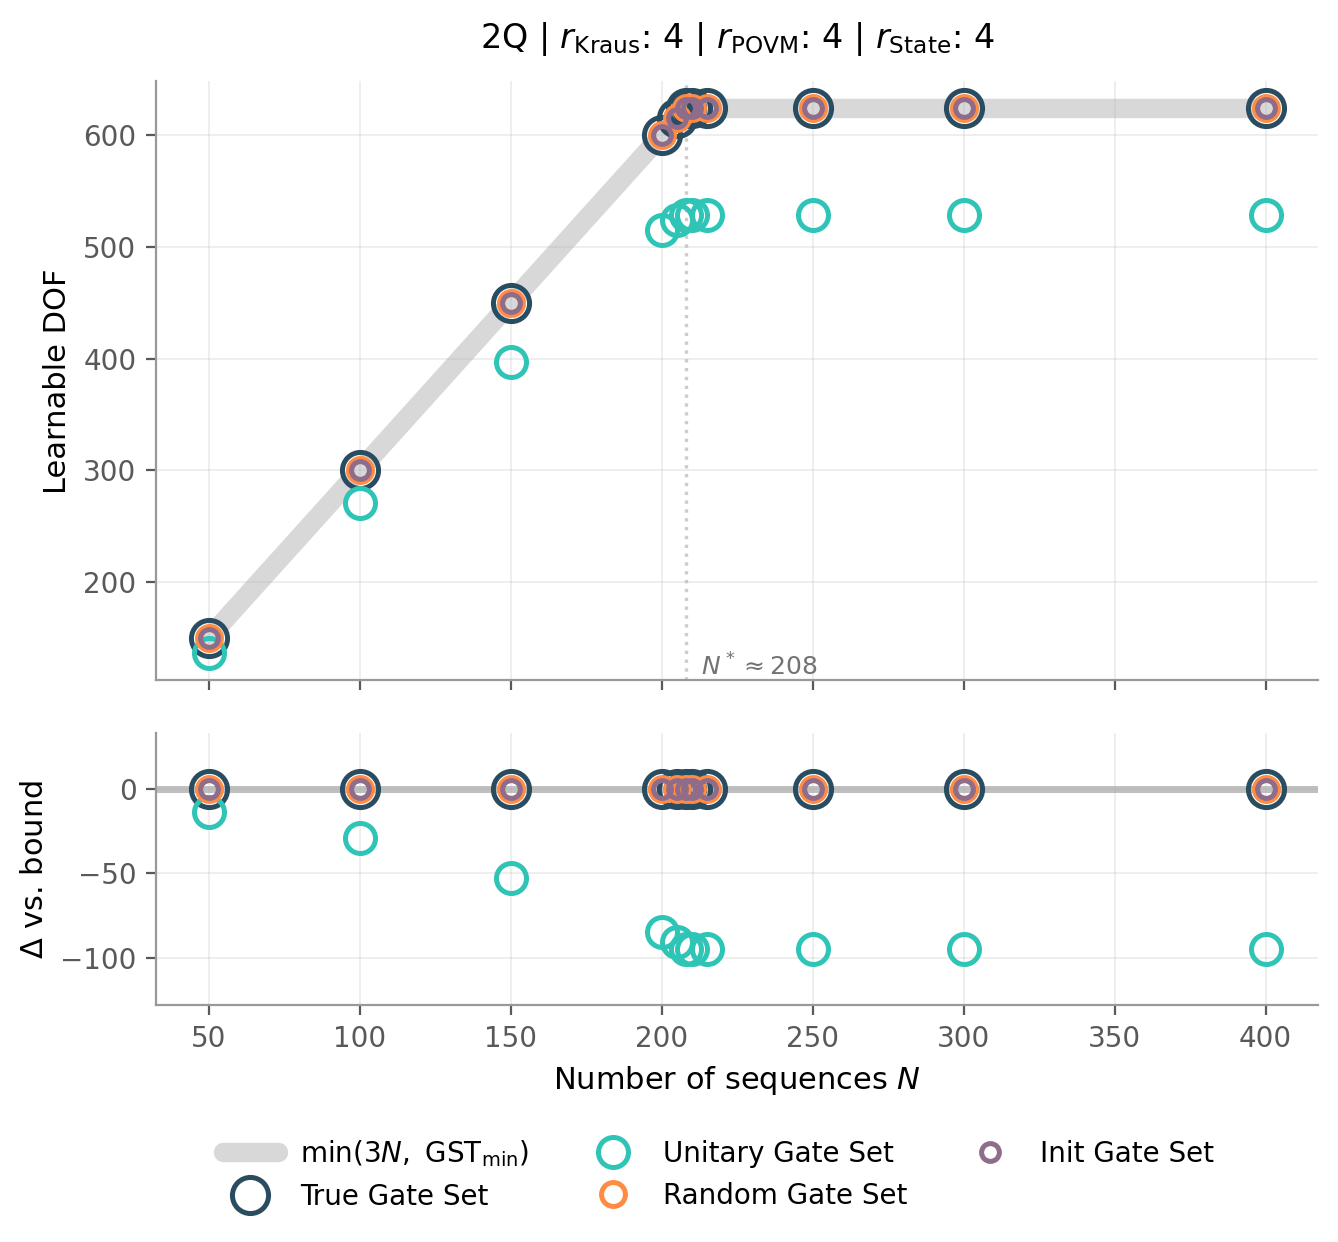

In [187]:
import matplotlib.pyplot as plt

# Ordered, harmonious subset instead of the full palette's clashing hues
SERIES_COLOURS = ["#294C60", "#2EC4B6", "#FF8C42", "#8E6C8A", "#4A4E69"]

series = list(zip(ranks_arrays[1:], labels_array[1:], SERIES_COLOURS))
n = len(series)

fig, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(7.5, 6), dpi=200, sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1], "hspace": 0.12},
)

def draw(ax, values_fn):
    for i, (ranks, label, colour) in enumerate(series):
        ax.plot(
            number_of_sequences_list, values_fn(ranks),
            linestyle="none",
            marker="o",                      # one shape for everything
            markersize=13 - 2.2 * i,         # nested rings
            markerfacecolor="none",          # open markers -> all layers visible
            markeredgecolor=colour,
            markeredgewidth=1.8,
            label=label,
        )

ax0.plot(number_of_sequences_list, ranks_expected,
         color="0.75", linewidth=7, alpha=0.6, solid_capstyle="round",
         zorder=0, label=r"$\min(3N,\ \mathrm{GST}_{\min})$")
draw(ax0, lambda r: r)

ax1.axhline(0, color="0.75", linewidth=2.5, zorder=0)
draw(ax1, lambda r: [a - b for a, b in zip(r, ranks_expected)])

for ax in (ax0, ax1):
    ax.grid(alpha=0.25, linestyle="-", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("0.6")
    ax.spines["bottom"].set_color("0.6")
    ax.tick_params(colors="0.35", labelsize=10)

n_star = (min_expected + 1) / 3
ax0.axvline(n_star, color="0.8", linestyle=":", linewidth=1.2, zorder=0)
ax0.text(n_star, ax0.get_ylim()[0], rf"  $N^*\approx{n_star:.0f}$",
         va="bottom", fontsize=9, color="0.45")

ax0.set_ylabel("Learnable DOF", fontsize=11)
ax0.set_title(title_general, fontsize=12, pad=12)
ax1.set_ylabel(r"$\Delta$ vs. bound", fontsize=11)
ax1.set_xlabel("Number of sequences $N$", fontsize=11)
# ax1.set_yticks(range(min(0, min_expected + 50), 1))   # replace with an explicit integer range
ax1.margins(y=0.35)

handles, labels = ax0.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.02),
           ncol=3, frameon=False, fontsize=10)
fig.tight_layout()

# Practical identifiability

Now we verified structural identifiability, we shift our focus to something more interesting practically speaking. We want to study the fisher spectrum across the experiment design. This means, how does the spectrum change as we increase the number of sequences, and the length of the sequences.

Changing the number of shots does not matter since the eigenvalues are $\lambda_k \propto m$. Instead, we should plot $\lambda_k/m$ and draw horizontal lines for different shot budgets. The $n_{eff}(\epsilon)$ is the number of eigenvalues whose cramer rao bound for the standard deviation is below a certain threshold $\epsilon$.

In [ ]:
# get the eigenvalues from all the results that we computed previously
results_true_gate_set[0].keys()

dict_keys(['rank', 'singular_values', 'num_independent_data', 'dim_tangent_space', 'fisher_eigenvalues'])

In [198]:
def compute_scaled_eigenvalues(results, num_shots):
    return [result["fisher_eigenvalues"][:result["rank"]]/num_shots for result in results]

In [ ]:
results_true_gate_set_all = results_true_gate_set + results_true_gate_set_longer_sequences

scaled_eigenvalues_true_gate_set_1000_shots = compute_scaled_eigenvalues(results_true_gate_set_all, num_shots)

In [183]:
shots_list = [1e2, 1e3, 1e4, 1e5]
epsilon = 1e-2
n_eff = {m: [int((lam > 1 / (m * epsilon**2)).sum()) for lam in scaled_eigenvalues_true_gate_set_1000_shots]
         for m in shots_list}

In [194]:
depth_list = [6, 8, 14, 16, 20, 22] # L_MAX

In [195]:
results_true_gate_set_1000_shots_vs_depths = compute_results_for_all_depths(depth_list=depth_list, gate_set_psd=noisy_gate_set_psd, number_of_sequences=1000, num_shots=num_shots, seed=None) # fix at 1000 sequences 

Computing results for sequence length 6... (1/6)
Number of possible sequences without replacement for the given sequence        length range is lower than the desired total number of sequences
Computing results for sequence length 8... (2/6)
Computing results for sequence length 14... (3/6)
Computing results for sequence length 16... (4/6)
Computing results for sequence length 20... (5/6)
Computing results for sequence length 22... (6/6)


In [248]:
results_true_gate_set_600_shots_vs_depths = compute_results_for_all_depths(depth_list=depth_list, gate_set_psd=noisy_gate_set_psd, number_of_sequences=600, num_shots=num_shots, seed=None) # fix at 600 sequences

Computing results for sequence length 6... (1/6)
Number of possible sequences without replacement for the given sequence        length range is lower than the desired total number of sequences
Computing results for sequence length 8... (2/6)
Computing results for sequence length 14... (3/6)
Computing results for sequence length 16... (4/6)
Computing results for sequence length 20... (5/6)
Computing results for sequence length 22... (6/6)


In [249]:
scaled_eigenvalues_true_gate_set_1000_shots_vs_depths = compute_scaled_eigenvalues(results_true_gate_set_1000_shots_vs_depths, num_shots)

scaled_eigenvalues_true_gate_set_600_shots_vs_depths = compute_scaled_eigenvalues(results_true_gate_set_600_shots_vs_depths, num_shots)

In [184]:
number_of_sequences_all = number_of_sequences_list + longer_sequences_list

In [215]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.ticker import FuncFormatter, MaxNLocator

def make_violin_plot(y_values, x_values, shots_list=(1e2, 1e3, 1e4, 1e5), epsilon=1e-2,
                     xlabel=None, ylabel=r"$\lambda_k / m$", title=None,
                     face="#2EC4B6", edge="#294C60", ax=None):
    log_spectra = [np.log10(np.asarray(lam)) for lam in y_values]
    positions = np.arange(len(x_values))

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4.5), dpi=200)
    else:
        fig = ax.figure

    parts = ax.violinplot(log_spectra, positions=positions, widths=0.75,
                          showmedians=False, showextrema=False)
    for body in parts["bodies"]:
        body.set_facecolor(face)
        body.set_edgecolor(edge)
        body.set_linewidth(0.8)
        body.set_alpha(0.55)

    q1, med, q3 = np.array([np.percentile(v, [25, 50, 75]) for v in log_spectra]).T
    lo = np.array([v.min() for v in log_spectra])
    hi = np.array([v.max() for v in log_spectra])
    ax.vlines(positions, lo, hi, color=edge, lw=0.8, zorder=3)
    ax.vlines(positions, q1, q3, color=edge, lw=4, zorder=3)
    ax.scatter(positions, med, s=14, color="white", edgecolor=edge, linewidth=0.8, zorder=4)

    # Cramer-Rao: std <= eps along direction k iff lambda_k/m >= 1/(m eps^2)
    right_margin = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
    for m in shots_list:
        y = np.log10(1 / (m * epsilon**2))
        ax.axhline(y, color="0.55", ls=(0, (4, 3)), lw=0.7, zorder=0)
        ax.text(1.01, y, rf"$m=10^{{{np.log10(m):.0f}}}$", transform=right_margin,
                ha="left", va="center", fontsize=7, color="0.4", clip_on=False)

    top_margin = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    for pos, v in zip(positions, log_spectra):
        ax.text(pos, 1.01, len(v), transform=top_margin,
                ha="center", va="bottom", fontsize=6, color="0.5")
    ax.text(-0.01, 1.01, "rank", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=6, color="0.5")

    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: rf"$10^{{{y:.0f}}}$"))
    ax.set_xticks(positions, x_values)
    ax.set_xlim(positions[0] - 0.6, positions[-1] + 0.6)

    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("0.6")
    ax.tick_params(colors="0.35", labelsize=9)
    ax.grid(axis="y", alpha=0.25, lw=0.5)
    ax.set_axisbelow(True)

    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title, fontsize=10, pad=14)
    fig.tight_layout()
    return fig, ax, 10 ** med

In [239]:
def compute_n_eff(scaled_eigenvalues, shots_list, epsilon):
    return {m: np.array([(np.asarray(lam) >= 1 / (m * epsilon**2)).sum() for lam in scaled_eigenvalues])
            for m in shots_list}

def make_n_eff_plot(scaled_eigenvalues, shots_list, epsilon, number_of_sequences, ax, xlabel: str = None):
    positions = np.arange(len(number_of_sequences))
    ranks = [len(lam) for lam in scaled_eigenvalues]
    n_eff = compute_n_eff(scaled_eigenvalues, shots_list, epsilon)

    ax.plot(positions, ranks, color="0.75", lw=5, alpha=0.6, solid_capstyle="round",
            zorder=0, label="rank (upper bound)")
    shades = plt.cm.Blues(np.linspace(0.4, 0.95, len(shots_list)))
    for (m, counts), colour in zip(n_eff.items(), shades):
        ax.plot(positions, counts, "o-", ms=3.5, lw=1.2, color=colour,
                label=rf"$m=10^{{{np.log10(m):.0f}}}$")

    ax.set_ylabel(r"$n_\mathrm{eff}(\epsilon)$")
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=7, frameon=False, ncol=len(shots_list) + 1, loc="upper center", bbox_to_anchor=(0.5, -0.25))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.25, lw=0.5)

/var/folders/1z/5qqk4w_97cz44w7c72srsw2c0000gq/T/ipykernel_97311/1054060695.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


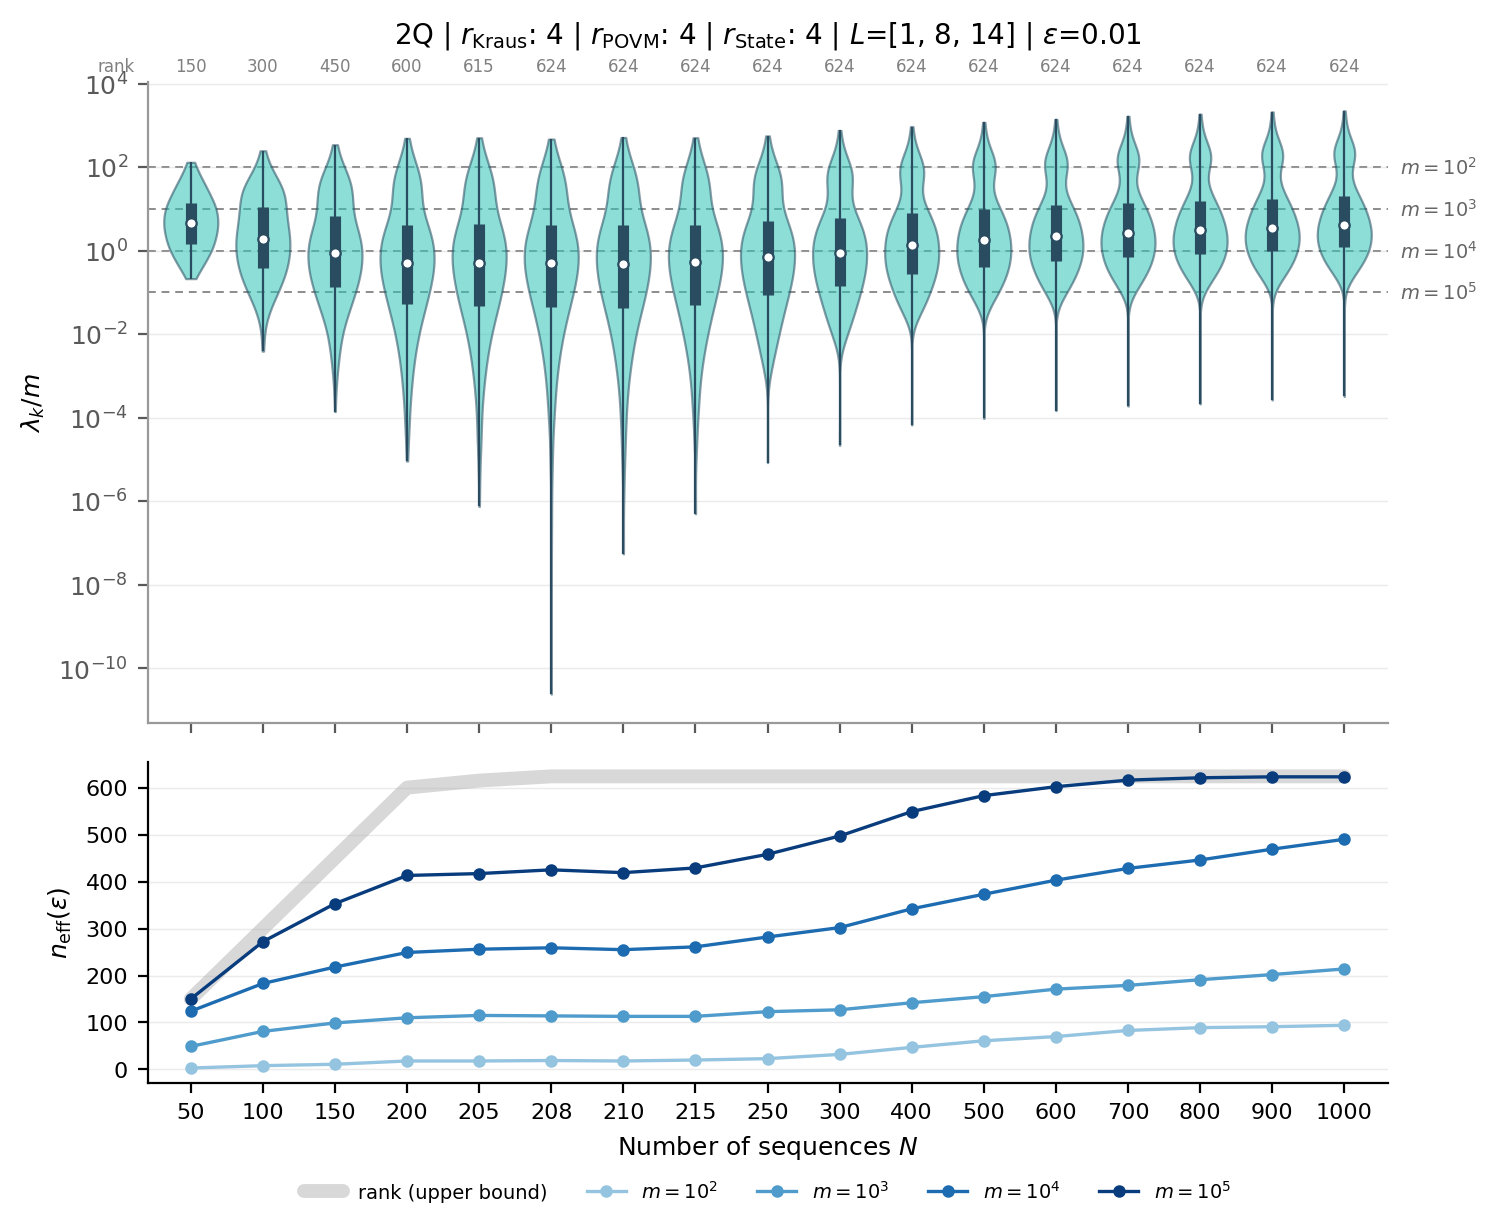

In [236]:
fig, (ax_v, ax_n) = plt.subplots(2, 1, figsize=(8, 6.5), dpi=200, sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08})

make_violin_plot(y_values=scaled_eigenvalues_true_gate_set_1000_shots,
                 x_values=number_of_sequences_all, shots_list=shots_list,
                 epsilon=epsilon, title=title, ax=ax_v)

make_n_eff_plot(scaled_eigenvalues_true_gate_set_1000_shots, shots_list, epsilon, number_of_sequences_all, ax=ax_n)

/var/folders/1z/5qqk4w_97cz44w7c72srsw2c0000gq/T/ipykernel_97311/1054060695.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


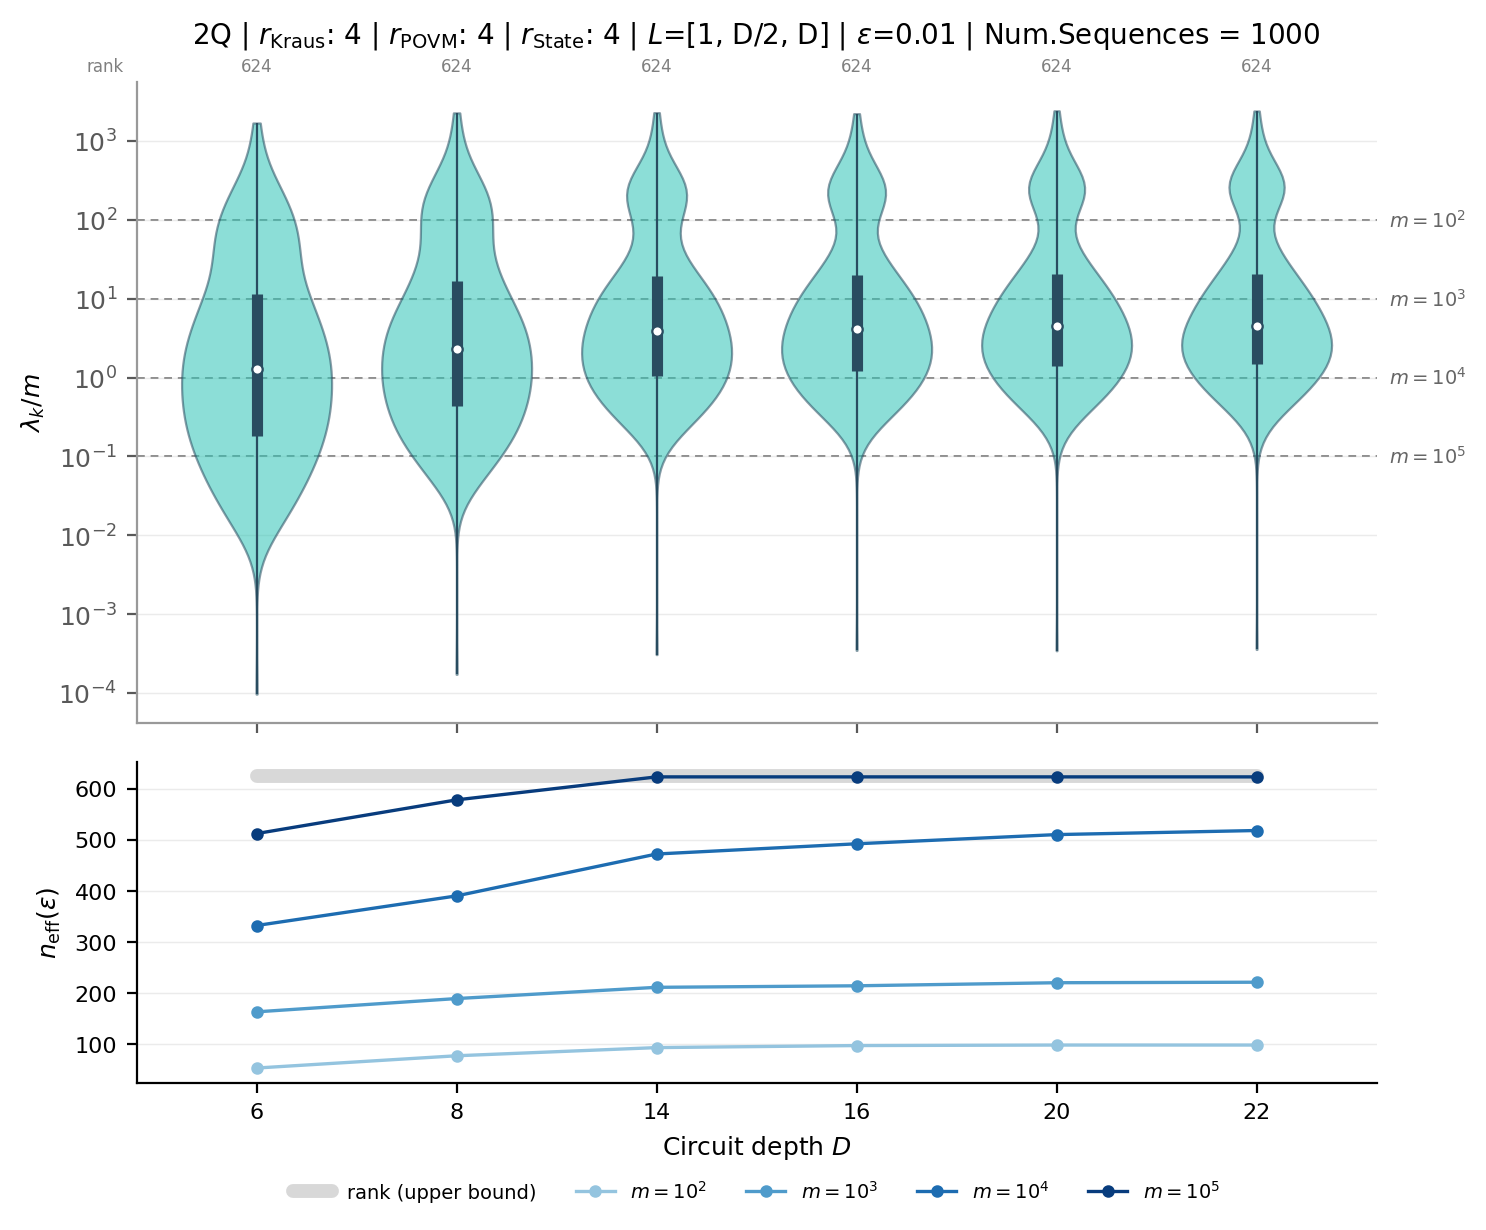

In [246]:
title_vs_depths = rf"{title_general} | $L$=[1, D/2, D] | $\epsilon$={epsilon} | Num.Sequences = 1000"

fig, (ax_v, ax_n) = plt.subplots(2, 1, figsize=(8, 6.5), dpi=200, sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1], "hspace": 0.08})

medians_vs_depths = make_violin_plot(
    y_values=scaled_eigenvalues_true_gate_set_1000_shots_vs_depths,
    x_values=depth_list,
    title=title_vs_depths,
    ax=ax_v
)

make_n_eff_plot(scaled_eigenvalues_true_gate_set_1000_shots_vs_depths, shots_list, epsilon, depth_list, ax=ax_n,
    xlabel="Circuit depth $D$")

In [244]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.transforms as mtransforms

TEAL_NAVY = LinearSegmentedColormap.from_list("teal_navy", ["#9FE3DC", "#2EC4B6", "#294C60", "#14232D"])

def make_required_shots_plot(scaled_eigenvalues, sweep_values, epsilon, gst_min,
                             shots_list=(1e2, 1e3, 1e4, 1e5), sweep_label="Number of sequences $N$",
                             cbar_ticks=None, log_norm=True, title=None, cmap=TEAL_NAVY, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 4.2), dpi=200)
    else:
        fig = ax.figure
    ax.set_xscale("log")

    norm_cls = LogNorm if log_norm else Normalize
    norm = norm_cls(min(sweep_values), max(sweep_values))

    for value, lam in zip(sweep_values, scaled_eigenvalues):
        required = np.sort(1 / (epsilon**2 * np.asarray(lam)))  # m needed so that lambda_k/m >= 1/(m eps^2)
        required = required[np.isfinite(required)]
        ax.step(required, np.arange(1, required.size + 1), where="post",
                color=cmap(norm(value)), lw=1.3, alpha=0.9)

    ax.axhline(gst_min, color="0.55", ls=(0, (4, 3)), lw=0.8, zorder=0)
    ax.text(0.01, gst_min, r"$\mathrm{GST}_\min$",
            transform=mtransforms.blended_transform_factory(ax.transAxes, ax.transData),
            va="bottom", fontsize=8, color="0.4")

    top = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    for m in shots_list:
        ax.axvline(m, color="0.85", lw=0.7, zorder=0)
        ax.text(m, 1.01, rf"$10^{{{np.log10(m):.0f}}}$", transform=top,
                ha="center", va="bottom", fontsize=7, color="0.5")

    ax.set_xlabel(r"Shots per circuit $m$", fontsize=10)
    ax.set_ylabel(rf"$n_\mathrm{{eff}}(\epsilon={epsilon})$", fontsize=10)
    if title is not None:
        ax.set_title(title, fontsize=10, pad=16)

    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("0.6")
    ax.tick_params(colors="0.35", labelsize=9)
    ax.grid(axis="y", alpha=0.25, lw=0.5)
    ax.set_axisbelow(True)

    cbar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02, aspect=30)
    cbar.set_label(sweep_label, fontsize=9)
    ticks = sweep_values if cbar_ticks is None else cbar_ticks
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([str(t) for t in ticks])
    cbar.minorticks_off()
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(labelsize=8, colors="0.35")
    fig.tight_layout()
    return fig, ax

(<Figure size 1400x840 with 2 Axes>,
 <Axes: title={'center': '2Q | $r_\\mathrm{Kraus}$: 4 | $r_\\mathrm{POVM}$: 4 | $r_\\mathrm{State}$: 4 | $L$=[1, D/2, D] | $\\epsilon$=0.01 | Num.Sequences = 1000'}, xlabel='Shots per circuit $m$', ylabel='$n_\\mathrm{eff}(\\epsilon=0.01)$'>)

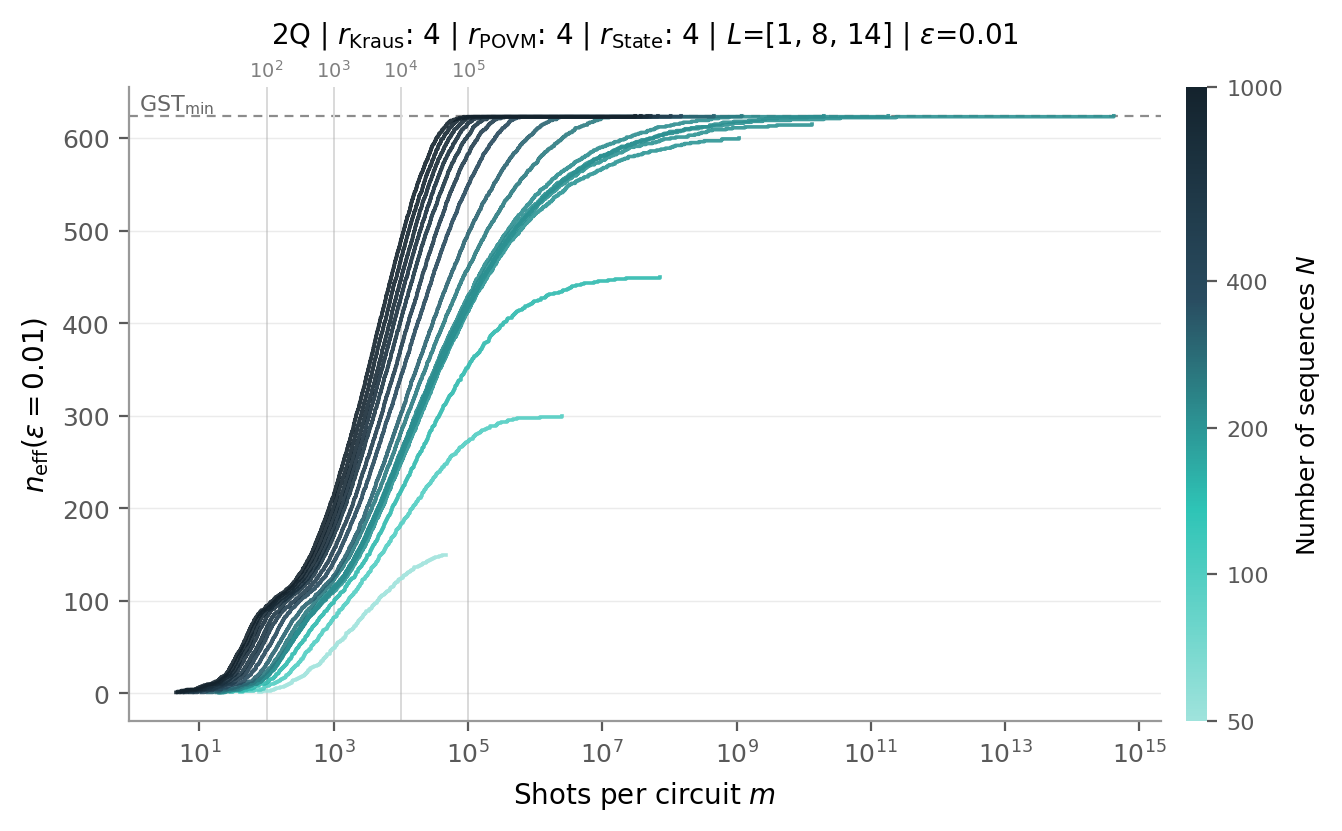

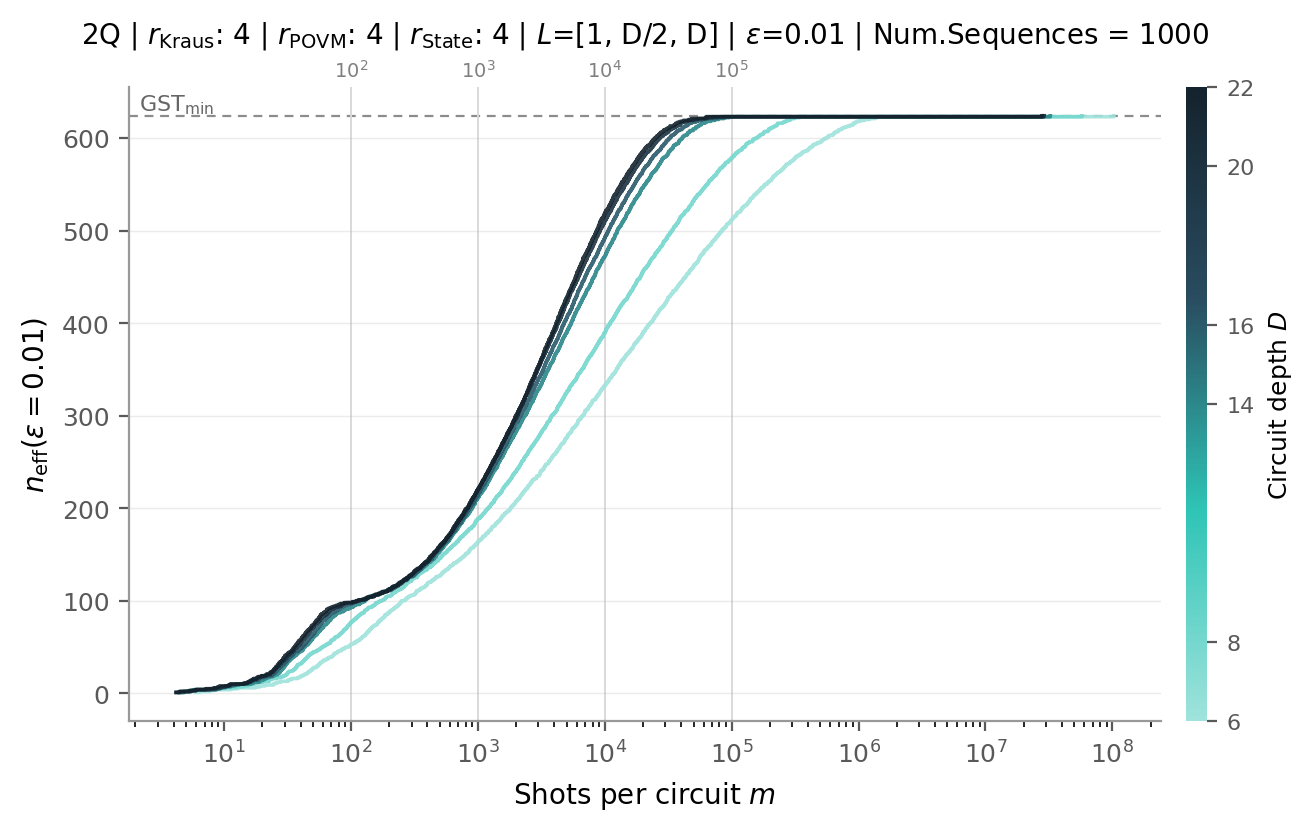

In [247]:
make_required_shots_plot(
    scaled_eigenvalues_true_gate_set_1000_shots, number_of_sequences_all,
    epsilon=epsilon, gst_min=min_expected + 1, shots_list=shots_list,
    cbar_ticks=[50, 100, 200, 400, 1000], title=title,
)

make_required_shots_plot(
    scaled_eigenvalues_true_gate_set_1000_shots_vs_depths, depth_list,
    epsilon=epsilon, gst_min=min_expected + 1, shots_list=shots_list,
    sweep_label="Circuit depth $D$", log_norm=False, title=title_vs_depths,
)

(<Figure size 1400x840 with 2 Axes>,
 <Axes: title={'center': '2Q | $r_\\mathrm{Kraus}$: 4 | $r_\\mathrm{POVM}$: 4 | $r_\\mathrm{State}$: 4 | $L$=[1, D/2, D] | $\\epsilon$=0.01 | Num.Sequences = 1000'}, xlabel='Shots per circuit $m$', ylabel='$n_\\mathrm{eff}(\\epsilon=0.01)$'>)

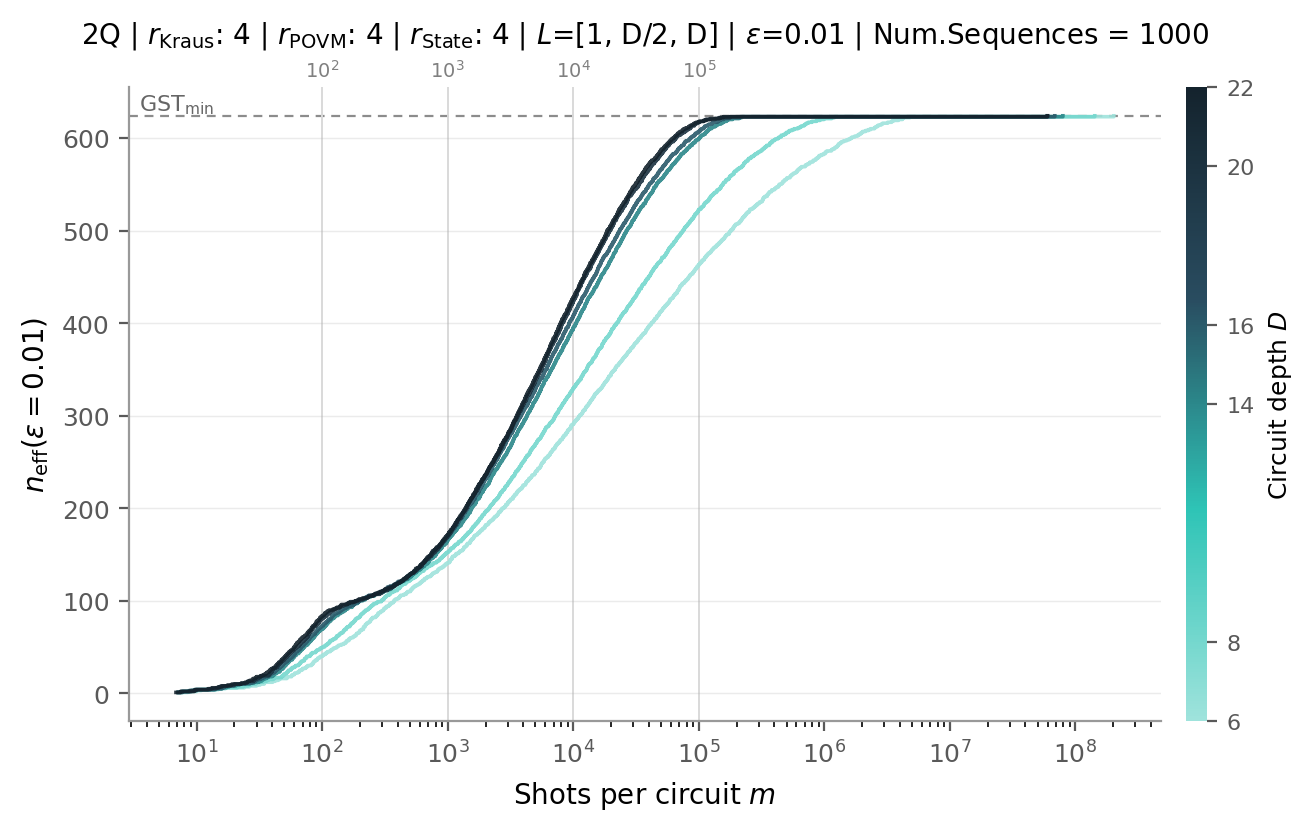

In [250]:
make_required_shots_plot(
    scaled_eigenvalues_true_gate_set_600_shots_vs_depths, depth_list,
    epsilon=epsilon, gst_min=min_expected + 1, shots_list=shots_list,
    sweep_label="Circuit depth $D$", log_norm=False, title=title_vs_depths,
)

In [154]:
factor = 4
16959 / (2**4 - 1) * factor  

4522.4

In [ ]:
# TODO:
# 1. Run more sequences here to see if the violin plots get better. Up to 1000 sequences?
# 2. Run the sweep so we can see the heatmap we are talking about
# 3. Relate these results to matrix elements?
# 4. Run the violin plot for different realizations to see if the results vary a lot.